# 03. 학습 상태 분류 — 인공신경망 vs 기존 규칙
**목표:** 최근 10분 센서 특징으로 지금 학습 상태(최적 / 졸림 / 산만)를 판단한다. 정답은 웹앱에 직접 남긴 집중도·졸림 기록이다.

**비교할 방법**
- 기존 규칙: 데이터 수집 기간 동안 장치가 실제로 켠 신호등 색 (`state` 열)
- k-최근접 이웃(k-NN), 결정 트리, 로지스틱 회귀
- **인공신경망(MLP)**: 은닉층 2개(16, 8), ReLU — 장치(ESP32)에 그대로 넣을 수 있는 구조

**특징 묶음 비교:** 기본 8개(소리 크기·변동·급증, CO₂ 평균·기울기, 조도, 온도, 습도) vs **기본 8개 + 주파수 특징 3개**(말소리 대역 비율, 스펙트럼 평탄도, 스펙트럼 중심)

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.neural_network import MLPClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
from sklearn.inspection import permutation_importance
from common import *

lab = pd.read_csv(f"{PROC}/labeled.csv", encoding="utf-8-sig")
F8 = ["f_" + c for c in BASE_FEATS]; F11 = F8 + ["f_" + c for c in SPEC_FEATS]
lab = lab.dropna(subset=F11)
y = lab["state_label"].astype(int).to_numpy(); g = lab["group"].to_numpy()
classes = sorted(np.unique(y))
print("상태별 10초 기록 수:", {STATE_KO[c]: int((y == c).sum()) for c in classes})
print("라벨(묶음) 수:", len(np.unique(g)))
if 1 not in classes: print("※ 측정 기간에 '졸림'(졸림 4 이상) 기록이 없어 최적·산만 두 상태로 학습한다.")

상태별 10초 기록 수: {'최적': 358, '산만': 332}
라벨(묶음) 수: 9
※ 측정 기간에 '졸림'(졸림 4 이상) 기록이 없어 최적·산만 두 상태로 학습한다.


## 평가 방법 — 라벨 하나씩 빼서 평가(Leave-One-Group-Out)
같은 라벨 구간의 10초 기록들은 서로 매우 비슷하다. 섞어서 나누면 '거의 같은 기록'을 맞히는 셈이라 정확도가 부풀려진다. 그래서 **라벨 구간 하나를 통째로 빼서 평가하고 나머지로 학습**하는 것을 라벨 수만큼 반복한다.

In [2]:
def models():
    return {
        "k-NN (k=15)": make_pipeline(StandardScaler(), KNeighborsClassifier(15)),
        "결정 트리 (깊이 3)": DecisionTreeClassifier(max_depth=3, random_state=0),
        "로지스틱 회귀": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, C=.5)),
        "인공신경망 MLP (16,8)": make_pipeline(StandardScaler(), MLPClassifier((16, 8), activation="relu", alpha=1e-2,
                                                                         max_iter=2000, random_state=0)),
    }

logo = LeaveOneGroupOut()
rows, preds = [], {}
rule = lab["state"].astype(int).to_numpy()
rows.append({"방법": "기존 규칙(장치 신호등)", "특징": "-", "정확도": accuracy_score(y, rule),
             "macro F1": f1_score(y, rule, average="macro", labels=classes), "라벨 단위 정확도": np.nan})
preds[("기존 규칙(장치 신호등)", "-")] = rule
for fname, F in [("기본 8개", F8), ("기본+주파수 11개", F11)]:
    for mname, _ in models().items():
        p = np.zeros_like(y)
        for tr, te in logo.split(lab[F], y, g):
            if len(np.unique(y[tr])) < 2: p[te] = y[tr][0]; continue
            m = models()[mname].fit(lab[F].iloc[tr], y[tr]); p[te] = m.predict(lab[F].iloc[te])
        # 라벨 단위: 한 라벨 구간의 예측 중 다수결
        vote = pd.Series(p).groupby(g).agg(lambda s: s.mode()[0]); truth = pd.Series(y).groupby(g).first()
        rows.append({"방법": mname, "특징": fname, "정확도": accuracy_score(y, p),
                     "macro F1": f1_score(y, p, average="macro", labels=classes),
                     "라벨 단위 정확도": (vote == truth).mean()})
        preds[(mname, fname)] = p
res = pd.DataFrame(rows).round(3); print(res.to_string(index=False))
res.to_csv(f"{RES}/03_classifier_scores.csv", index=False, encoding="utf-8-sig")

              방법         특징   정확도  macro F1  라벨 단위 정확도
   기존 규칙(장치 신호등)          - 0.091     0.124        NaN
     k-NN (k=15)      기본 8개 0.403     0.368      0.444
    결정 트리 (깊이 3)      기본 8개 0.374     0.367      0.444
         로지스틱 회귀      기본 8개 0.532     0.529      0.556
인공신경망 MLP (16,8)      기본 8개 0.539     0.536      0.556
     k-NN (k=15) 기본+주파수 11개 0.406     0.366      0.556
    결정 트리 (깊이 3) 기본+주파수 11개 0.291     0.266      0.333
         로지스틱 회귀 기본+주파수 11개 0.520     0.513      0.667
인공신경망 MLP (16,8) 기본+주파수 11개 0.564     0.561      0.667


## 혼동 행렬 — 어디서 틀리는가

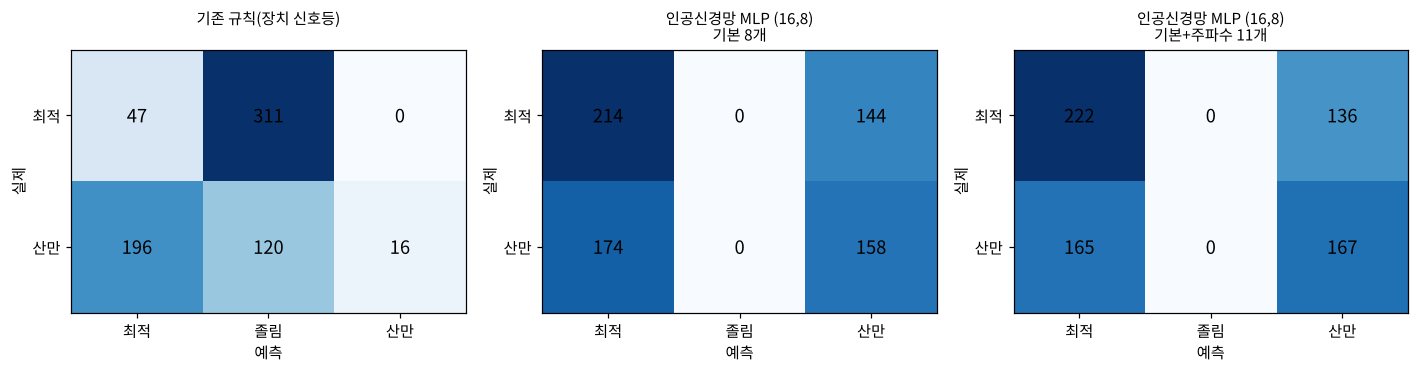

In [3]:
show = [("기존 규칙(장치 신호등)", "-"), ("인공신경망 MLP (16,8)", "기본 8개"), ("인공신경망 MLP (16,8)", "기본+주파수 11개")]
fig, ax = plt.subplots(1, 3, figsize=(13, 4))
ALL = [0, 1, 2]                                   # 예측은 세 상태 모두 나올 수 있음(규칙은 '졸림'도 켬)
for a, key in zip(ax, show):
    cm = confusion_matrix(y, preds[key], labels=ALL)[classes]
    a.imshow(cm, cmap="Blues")
    for i in range(len(classes)):
        for j in range(3): a.text(j, i, cm[i, j], ha="center", va="center", fontsize=12)
    a.set_xticks(range(3)); a.set_xticklabels([STATE_KO[c] for c in ALL])
    a.set_yticks(range(len(classes))); a.set_yticklabels([STATE_KO[c] for c in classes])
    a.set_xlabel("예측"); a.set_ylabel("실제"); a.set_title(f"{key[0]}\n{key[1] if key[1] != '-' else ''}", fontsize=10)
plt.tight_layout(); plt.savefig(f"{RES}/03_confusion.png", dpi=150); plt.show()

## 어떤 특징이 판단에 중요했나 (순열 중요도)
특징 하나의 값을 무작위로 섞었을 때 정확도가 얼마나 떨어지는지로 중요도를 잰다.

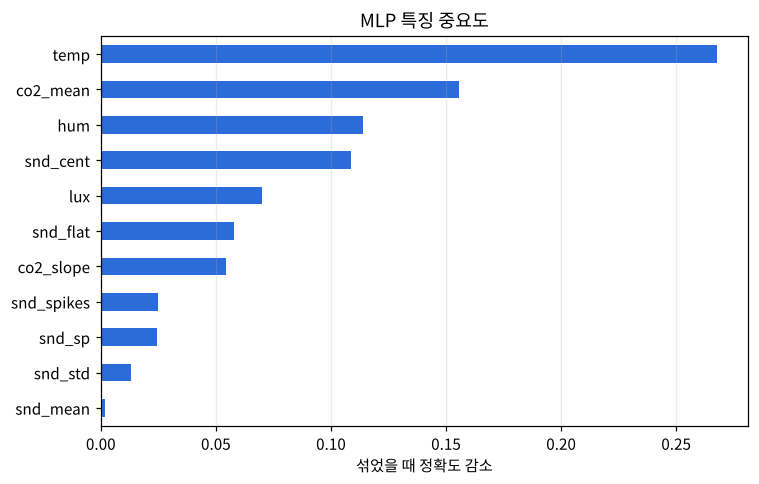

temp          0.268
co2_mean      0.156
hum           0.114
snd_cent      0.109
lux           0.070
snd_flat      0.058
co2_slope     0.054
snd_spikes    0.025
snd_sp        0.024
snd_std       0.013
snd_mean      0.002


In [4]:
mlp11 = models()["인공신경망 MLP (16,8)"].fit(lab[F11], y)
pi = permutation_importance(mlp11, lab[F11], y, n_repeats=20, random_state=0, scoring="accuracy")
imp = pd.Series(pi.importances_mean, index=[c[2:] for c in F11]).sort_values()
fig, a = plt.subplots(figsize=(7, 4.5)); imp.plot.barh(ax=a, color="#2b6cd8"); a.set_xlabel("섞었을 때 정확도 감소")
a.set_title("MLP 특징 중요도"); a.grid(alpha=.25, axis="x")
plt.tight_layout(); plt.savefig(f"{RES}/03_importance.png", dpi=150); plt.show()
print(imp.sort_values(ascending=False).round(3).to_string())

## 결정 트리 모양 (사람이 읽을 수 있는 규칙)

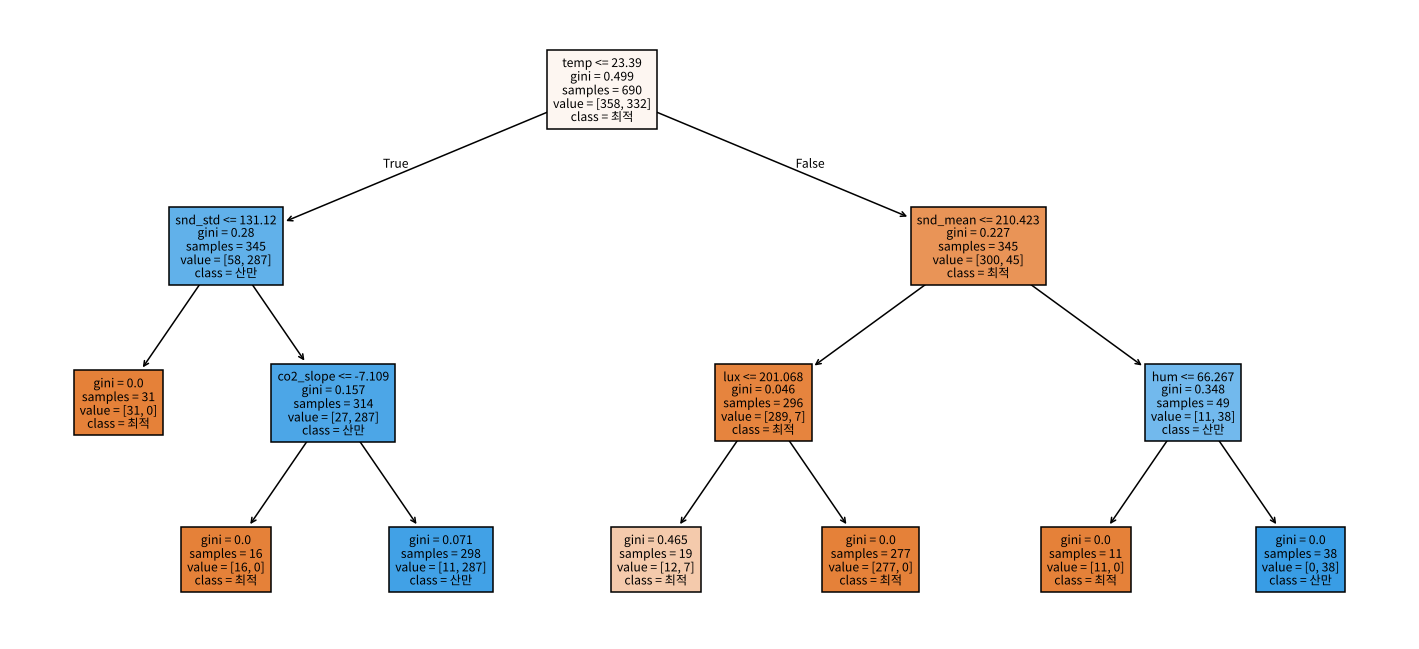

In [5]:
dt = DecisionTreeClassifier(max_depth=3, random_state=0).fit(lab[F11], y)
fig, a = plt.subplots(figsize=(13, 6))
plot_tree(dt, feature_names=[c[2:] for c in F11], class_names=[STATE_KO[c] for c in dt.classes_], filled=True, ax=a, fontsize=8)
plt.tight_layout(); plt.savefig(f"{RES}/03_tree.png", dpi=150); plt.show()

## 전체 라벨로 다시 학습해 저장
05번에서 이 모델이 학습 범위(11/14 오후 2시간) 밖에서도 쓸 수 있는지 확인한다.

In [6]:
import joblib
sc8 = StandardScaler().fit(lab[F8])
mlp8 = MLPClassifier((16, 8), activation="relu", alpha=1e-2, max_iter=2000, random_state=0).fit(sc8.transform(lab[F8]), y)
joblib.dump({"model": mlp8, "scaler": sc8, "feats": F8}, f"{PROC}/state_mlp8.joblib")
joblib.dump({"model": mlp11, "feats": F11}, f"{PROC}/state_mlp11.joblib")
print("학습 정확도(참고):", round(accuracy_score(y, mlp8.predict(sc8.transform(lab[F8]))), 3))

학습 정확도(참고): 0.999
